# CommerceIQ — Week 1 E-commerce Analysis

**Dataset:** Olist Brazilian E-Commerce Public Dataset (cleaned project tables).  
**Grain:** `fact_order_items.csv` is order-item grain.  
**Revenue definition:** delivered item merchandise price (`price`); freight excluded. `total_payment_value` is order-grain and must not be summed over item rows.

Run from the repository root. The notebook uses project-relative paths and reproduces the headline KPI and charts.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'data' / 'cleaned' / 'fact_order_items.csv').exists():
    ROOT = ROOT.parent
FACT = ROOT / 'data' / 'cleaned' / 'fact_order_items.csv'
ORDERS = ROOT / 'data' / 'cleaned' / 'olist_orders_dataset.csv'
PAYMENTS = ROOT / 'data' / 'cleaned' / 'olist_order_payments_dataset.csv'
TRANSLATION = ROOT / 'data' / 'cleaned' / 'product_category_name_translation.csv'

fact = pd.read_csv(FACT, low_memory=False)
orders = pd.read_csv(ORDERS, parse_dates=['order_purchase_timestamp'])
payments = pd.read_csv(PAYMENTS)
translation = pd.read_csv(TRANSLATION)
fact['order_purchase_timestamp'] = pd.to_datetime(fact['order_purchase_timestamp'], errors='coerce')
delivered = fact.loc[fact['order_status'].eq('delivered')].copy()
delivered = delivered.merge(translation, on='product_category_name', how='left')
delivered['category_en'] = delivered['product_category_name_english'].fillna(delivered['product_category_name']).fillna('unknown')
delivered['month'] = delivered['order_purchase_timestamp'].dt.to_period('M').astype(str)
print('Fact rows:', len(fact), '| Delivered item rows:', len(delivered))

Fact rows: 112650 | Delivered item rows: 110197


## KPI summary

In [2]:
revenue = delivered['price'].sum()
order_count = delivered['order_id'].nunique()
customer_count = delivered['customer_unique_id'].nunique()
customer_orders = delivered.groupby('customer_unique_id')['order_id'].nunique()
repeat_customers = int((customer_orders > 1).sum())

kpi_summary = pd.DataFrame([
    ('Delivered item revenue (BRL)', revenue),
    ('Delivered orders', order_count),
    ('Average order value (BRL)', revenue / order_count),
    ('Delivered order items', len(delivered)),
    ('Unique delivered customers', customer_count),
    ('Repeat customers', repeat_customers),
    ('Repeat customer rate (%)', repeat_customers / customer_count * 100),
    ('Delivered freight (BRL)', delivered['freight_value'].sum()),
], columns=['KPI', 'Value'])
kpi_summary

,KPI,Value
0,Delivered item revenue (BRL),1.322150e+07
1,Delivered orders,9.647800e+04
2,Average order value (BRL),1.370416e+02
3,Delivered order items,1.101970e+05
4,Unique delivered customers,9.335800e+04
5,Repeat customers,2.801000e+03
6,Repeat customer rate (%),3.000278e+00
7,Delivered freight (BRL),2.198276e+06


## Monthly revenue trend

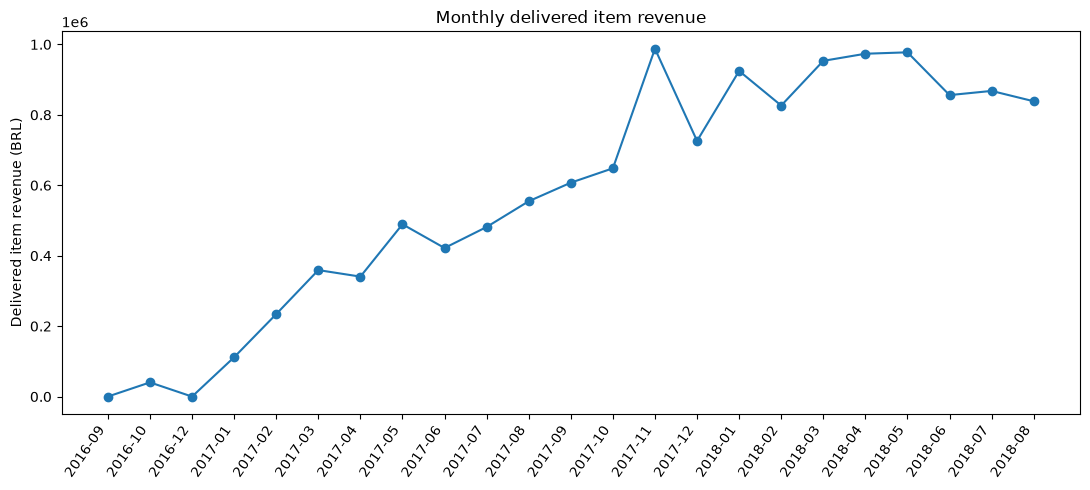

In [3]:
monthly = delivered.groupby('month', as_index=False)['price'].sum()
plt.figure(figsize=(11, 5))
plt.plot(monthly['month'], monthly['price'], marker='o')
plt.xticks(rotation=55, ha='right')
plt.ylabel('Delivered item revenue (BRL)')
plt.title('Monthly delivered item revenue')
plt.tight_layout()
plt.show()

## Category performance

In [4]:
category = (delivered.groupby('category_en', as_index=False)
            .agg(revenue=('price', 'sum'), units=('order_item_id', 'count'), orders=('order_id', 'nunique'))
            .sort_values('revenue', ascending=False))
category.head(10)

,category_en,revenue,units,orders
43,health_beauty,1233131.72,9465,8647
73,watches_gifts,1166176.98,5859,5495
7,bed_bath_table,1023434.76,10953,9272
67,sports_leisure,954852.55,8431,7530
15,computers_accessories,888724.61,7644,6530
39,furniture_decor,711927.69,8160,6307
49,housewares,615628.69,6795,5743
20,cool_stuff,610204.10,3718,3559
5,auto,578966.65,4140,3810
71,toys,471286.48,4030,3804


## Customer repeat behaviour

In [5]:
customer_summary = delivered.groupby('customer_unique_id').agg(
    orders=('order_id', 'nunique'), revenue=('price', 'sum'))
repeat_summary = pd.DataFrame({
    'metric': ['Unique delivered customers', 'Repeat customers', 'Repeat customer rate (%)'],
    'value': [len(customer_summary), int((customer_summary.orders > 1).sum()),
              (customer_summary.orders > 1).mean() * 100]
})
repeat_summary

,metric,value
0,Unique delivered customers,93358.000000
1,Repeat customers,2801.000000
2,Repeat customer rate (%),3.000278


## Payment mix and order status

In [6]:
payment_mix = payments.groupby('payment_type', as_index=False).agg(
    payment_value=('payment_value', 'sum'), orders=('order_id', 'nunique'))
status_mix = orders['order_status'].value_counts().rename_axis('order_status').reset_index(name='orders')
display(payment_mix.sort_values('payment_value', ascending=False))
display(status_mix)

,payment_type,payment_value,orders
1,credit_card,12542084.19,76505
0,boleto,2869361.27,19784
4,voucher,379436.87,3866
2,debit_card,217989.79,1528
3,not_defined,0.00,3


,order_status,orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


## Interpretation and limitations

- Revenue is merchandise item price for delivered order-items; freight is excluded and shown separately.
- Payment values are aggregated from the order-payment table, not summed from the item-grain fact table.
- Repeat-customer identity uses `customer_unique_id`, not `customer_id`.
- The source is historical (2016–2018); findings are descriptive, not current-market forecasts.
- Some source quality exceptions remain documented in `reports/data_quality_audit.csv`; review IDs are not globally unique by themselves, while the cleaning pipeline validates the composite `(order_id, review_id)` key.